<a href="https://colab.research.google.com/github/Rohit-Aroonslam/HCIA_Course/blob/main/HCIA_DL_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning Lab 7.2
## Building a Fully-Connected Neural Network from Scratch
Build, train and test a multi-layer neural network on the MNIST handwritten digit dataset using only NumPy, and compare four optimizers by their loss curves.

## 1.2.1 File parsing: unpack the code and dataset
Unzip Dataset.zip. The folder it creates holds the MNIST code files (train_mnist.py, load_mnist.py, multi_layer_net.py, layers.py, optimizer.py, util.py, functions.py, gradient.py) and the four compressed data files.

In [21]:
!unzip -q -o /content/Dataset.zip -d /content
!find /content -iname "train_mnist.py"

/content/Building a Fully-Connected Neural Network from Scratch/train_mnist.py


## Move into the project folder
Change into the unpacked folder so Python can import the lab's files.

In [22]:
%cd "/content/Building a Fully-Connected Neural Network from Scratch"
!ls

/content/Building a Fully-Connected Neural Network from Scratch
functions.py   mnist.pkl	   t10k-images-idx3-ubyte.gz   train_mnist.py
gradient.py    multi_layer_net.py  t10k-labels-idx1-ubyte.gz   util.py
layers.py      optimizer.py	   train-images-idx3-ubyte.gz
load_mnist.py  __pycache__	   train-labels-idx1-ubyte.gz


## 1.2.2 Loading the dataset
Use the load_mnist function to read the MNIST images and labels. It converts the compressed files into NumPy arrays, saves them as mnist.pkl on the first run, and scales the pixel values to the range 0 to 1.

In [23]:
from load_mnist import load_mnist

(x_train, t_train), (x_test, t_test) = load_mnist(normalize=True)

train_size = x_train.shape[0]   # number of training images
batch_size = 128                # images used in each training step
max_iterations = 1000           # number of training steps

In [24]:
#Check the data
print(x_train.shape, t_train.shape)
print(x_test.shape, t_test.shape)

(60000, 784) (60000, 10)
(10000, 784) (10000, 10)


## 1.2.3 Building the network structure
Create four optimizers (SGD, Momentum, AdaGrad, Adam) and one identical network for each, so their loss curves can be compared. Each network has 784 inputs, four hidden layers of 100 neurons and 10 outputs, one for each digit.

In [25]:
from multi_layer_net import MultiLayerNet
from optimizer import *

optimizers = {}   # one optimizer per entry
optimizers['SGD'] = SGD()
optimizers['Momentum'] = Momentum()
optimizers['AdaGrad'] = AdaGrad()
optimizers['Adam'] = Adam()

networks = {}     # one network per optimizer
train_loss = {}   # loss values recorded during training
for key in optimizers.keys():
    networks[key] = MultiLayerNet(
        input_size=784, hidden_size_list=[100, 100, 100, 100],
        output_size=10)
    train_loss[key] = []

In [26]:
#Checking the structure
print(list(networks['SGD'].layers.keys()))
print({k: v.shape for k, v in networks['SGD'].params.items()})

['Affine1', 'Activation_function1', 'Affine2', 'Activation_function2', 'Affine3', 'Activation_function3', 'Affine4', 'Activation_function4', 'Affine5']
{'W1': (784, 100), 'b1': (100,), 'W2': (100, 100), 'b2': (100,), 'W3': (100, 100), 'b3': (100,), 'W4': (100, 100), 'b4': (100,), 'W5': (100, 10), 'b5': (10,)}


## 1.2.4 Starting training
Train the four networks for 1,000 iterations. In each iteration, take a random batch of 128 training images, compute the gradients, update the weights with each optimizer and record the loss. The loss of every optimizer is printed every 100 iterations.

In [27]:
import numpy as np

for i in range(max_iterations):
    batch_mask = np.random.choice(train_size, batch_size)  # random indices
    x_batch = x_train[batch_mask]                          # random training images
    t_batch = t_train[batch_mask]                          # their labels

    # Parameter optimization
    for key in optimizers.keys():
        grads = networks[key].gradient(x_batch, t_batch)
        optimizers[key].update(networks[key].params, grads)

        loss = networks[key].loss(x_batch, t_batch)
        train_loss[key].append(loss)

    if i % 100 == 0:
        print("===========" + "iteration:" + str(i) + "===========")
        for key in optimizers.keys():
            loss = networks[key].loss(x_batch, t_batch)
            print(key + ":" + str(loss))

===========iteration:0===========
SGD:2.408044975030241
Momentum:2.3224200035903384
AdaGrad:2.1540746831460353
Adam:2.221670648941099
===========iteration:100===========
SGD:1.5618041994384426
Momentum:0.274610581313894
AdaGrad:0.08132951975801782
Adam:0.17121772660125312
===========iteration:200===========
SGD:0.8171075533094739
Momentum:0.18598345899971475
AdaGrad:0.09308208828682243
Adam:0.13938121369116338
===========iteration:300===========
SGD:0.6958295111500477
Momentum:0.29392661785772567
AdaGrad:0.10936902614191506
Adam:0.21170824026369328
===========iteration:400===========
SGD:0.5058478792340806
Momentum:0.14198460279302672
AdaGrad:0.08501073770553112
Adam:0.1225138712809783
===========iteration:500===========
SGD:0.4248774258577148
Momentum:0.17805184510206112
AdaGrad:0.08567052765035278
Adam:0.1329852347983084
===========iteration:600===========
SGD:0.3015157902171348
Momentum:0.11124828195687958
AdaGrad:0.04118911134003456
Adam:0.09843215788617686
===========iteration:700

## 1.2.5 Drawing the graph
Plot the loss of each optimizer against the training iterations. The smooth_curve function from util.py averages out the noise so the trends are easier to compare.

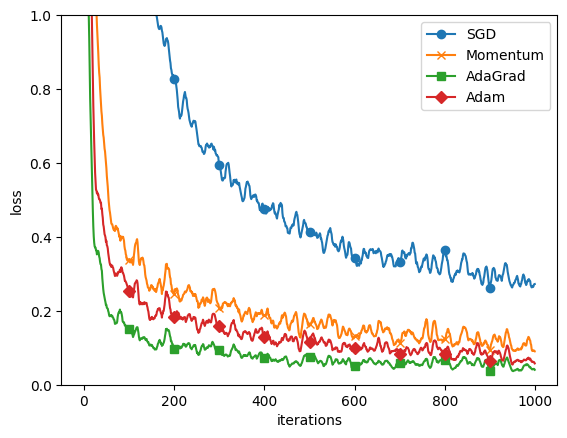

In [28]:
import matplotlib.pyplot as plt
from util import smooth_curve

markers = {"SGD": "o", "Momentum": "x", "AdaGrad": "s", "Adam": "D"}
x = np.arange(max_iterations)
for key in optimizers.keys():
    plt.plot(x, smooth_curve(train_loss[key]), marker=markers[key], markevery=100, label=key)
plt.xlabel("iterations")
plt.ylabel("loss")
plt.ylim(0, 1)
plt.legend()
plt.show()

## 1.3 Questions
### Question 1: How do I change the learning rate in the code? Use different learning rate settings and observe the loss curve.
The learning rate is set when each optimizer is created, for example SGD(lr=0.1). Train the same network several times with different learning rates and compare the curves.

In [29]:
#Check how the learning rate is named in your copy of the code(reads it from the file instead of guessing)
import inspect
import optimizer
for name in ["SGD", "Momentum", "AdaGrad", "Adam"]:
    print(name, inspect.signature(getattr(optimizer, name).__init__))

SGD (self, lr=0.01)
Momentum (self, lr=0.01, momentum=0.9)
AdaGrad (self, lr=0.01)
Adam (self, lr=0.001, beta1=0.9, beta2=0.999)


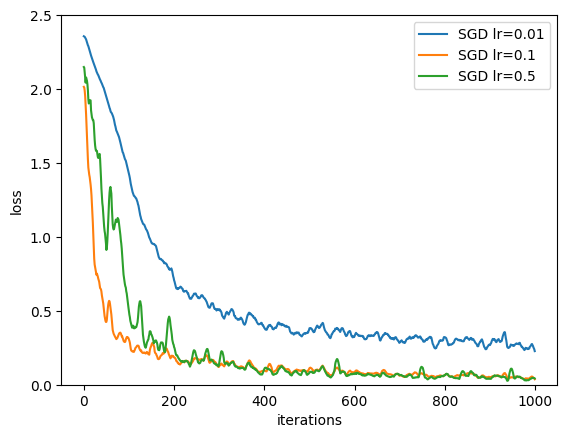

In [30]:
#Trains one SGD network three times with learning rates 0.01, 0.1 and 0.5:
def train_with(make_optimizer, iterations=1000):
    np.random.seed(0)   # same starting weights and batches for a fair comparison
    net = MultiLayerNet(input_size=784, hidden_size_list=[100, 100, 100, 100], output_size=10)
    opt = make_optimizer()
    losses = []
    for i in range(iterations):
        mask = np.random.choice(train_size, batch_size)
        x_b, t_b = x_train[mask], t_train[mask]
        grads = net.gradient(x_b, t_b)
        opt.update(net.params, grads)
        losses.append(net.loss(x_b, t_b))
    return losses

for lr in [0.01, 0.1, 0.5]:
    losses = train_with(lambda: SGD(lr=lr))
    plt.plot(smooth_curve(losses), label="SGD lr=" + str(lr))
plt.xlabel("iterations")
plt.ylabel("loss")
plt.ylim(0, 2.5)
plt.legend()
plt.show()

### Question 2: Add a test module to generate the test accuracy at different phases
Retrain the four networks from scratch, and every 100 iterations measure each network's accuracy on the 10,000 test images. The test set is only used for measuring, never for training.

In [31]:
# Fresh optimizers and networks, so every run starts from scratch
optimizers = {'SGD': SGD(), 'Momentum': Momentum(), 'AdaGrad': AdaGrad(), 'Adam': Adam()}
networks = {key: MultiLayerNet(input_size=784, hidden_size_list=[100, 100, 100, 100], output_size=10)
            for key in optimizers.keys()}
train_loss = {key: [] for key in optimizers.keys()}
test_acc = {key: [] for key in optimizers.keys()}   # test accuracy at each phase
phases = []                                         # iterations at which accuracy was measured

for i in range(max_iterations):
    # Test module: measure test accuracy every 100 iterations
    if i % 100 == 0:
        phases.append(i)
        for key in optimizers.keys():
            test_acc[key].append(networks[key].accuracy(x_test, t_test))

    batch_mask = np.random.choice(train_size, batch_size)
    x_batch = x_train[batch_mask]
    t_batch = t_train[batch_mask]

    for key in optimizers.keys():
        grads = networks[key].gradient(x_batch, t_batch)
        optimizers[key].update(networks[key].params, grads)
        train_loss[key].append(networks[key].loss(x_batch, t_batch))

# Final test after the last iteration
phases.append(max_iterations)
for key in optimizers.keys():
    test_acc[key].append(networks[key].accuracy(x_test, t_test))

In [32]:
#show the accuracies as a table
import pandas as pd
pd.DataFrame(test_acc, index=phases).rename_axis("iteration")

,SGD,Momentum,AdaGrad,Adam
iteration,,,,
0,0.0975,0.0922,0.0894,0.1210
100,0.6244,0.9005,0.9323,0.9132
200,0.8018,0.9265,0.9482,0.9393
300,0.8550,0.9340,0.9516,0.9463
400,0.8778,0.9347,0.9570,0.9575
500,0.8892,0.9466,0.9541,0.9590
600,0.8995,0.9404,0.9616,0.9542
700,0.9028,0.9536,0.9603,0.9617
800,0.9100,0.9561,0.9664,0.9637


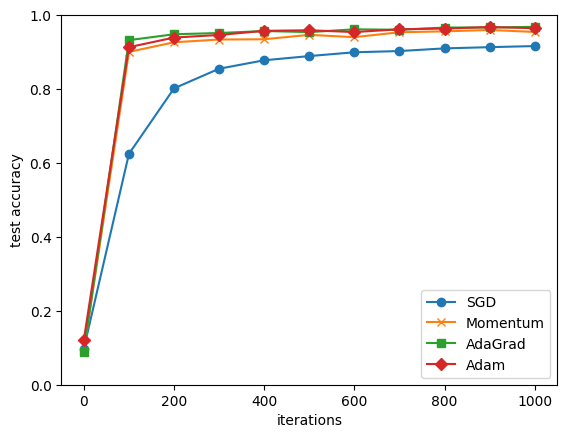

In [33]:
#plot accuracy against iterations
for key in optimizers.keys():
    plt.plot(phases, test_acc[key], marker=markers[key], label=key)
plt.xlabel("iterations")
plt.ylabel("test accuracy")
plt.ylim(0, 1)
plt.legend()
plt.show()